In [1]:
import pandas as pd

pd.set_option('display.max_columns', 200)

In [2]:
from pathlib import Path

dataset = Path('3. Dataset/data_bankruptcy.csv')
if not dataset.is_file():
    dataset = Path('..') / dataset
df = pd.read_csv(dataset)
df

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,1.256969e-04,0.000000e+00,0.458143,7.250725e-04,0.000000,0.147950,0.147950,0.147950,0.169141,0.311664,0.017560,0.095921,0.138736,0.022102,0.848195,0.688979,0.688979,0.217535,4.980000e+09,0.000327,0.263100,0.363725,0.002259,0.001208,0.629951,0.021266,0.207576,0.792424,0.005024,0.390284,0.006479,0.095885,0.137757,0.398036,0.086957,0.001814,0.003487,1.820926e-04,1.165007e-04,0.032903,0.034164,0.392913,0.037135,0.672775,0.166673,0.190643,0.004094,0.001997,1.473360e-04,0.147308,0.334015,0.276920,0.001036,0.676269,0.721275,0.339077,2.559237e-02,0.903225,0.002022,0.064856,7.010000e+08,6.550000e+09,0.593831,4.580000e+08,0.671568,0.424206,0.676269,0.339077,0.126549,0.637555,0.458609,0.520382,0.312905,0.118250,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,2.897851e-04,0.000000e+00,0.461867,6.470647e-04,0.000000,0.182251,0.182251,0.182251,0.208944,0.318137,0.021144,0.093722,0.169918,0.022080,0.848088,0.689693,0.689702,0.217620,6.110000e+09,0.000443,0.264516,0.376709,0.006016,0.004039,0.635172,0.012502,0.171176,0.828824,0.005059,0.376760,0.005835,0.093743,0.168962,0.397725,0.064468,0.001286,0.004917,9

# 1. Data Preparation

## 1.1 Data Quality Check

Checks performed: structure, missing values, duplicates, invalid values (inf), constant columns, target balance, and outliers.

In [ ]:
# Column names contain leading spaces in the raw file -> strip them
df.columns = df.columns.str.strip()

print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
print('\nData types:')
print(df.dtypes.value_counts())

In [ ]:
import numpy as np

# Missing values, duplicates, infinite values
missing = df.isna().sum()
print(f'Total missing values : {missing.sum()}')
print(f'Columns with missing : {(missing > 0).sum()}')
print(f'Duplicate rows       : {df.duplicated().sum()}')
print(f'Infinite values      : {np.isinf(df.select_dtypes("number")).sum().sum()}')

# Constant columns (no information)
n_unique = df.nunique()
print(f'Constant columns     : {n_unique[n_unique <= 1].index.tolist()}')

In [ ]:
# Target balance
counts = df['Bankrupt?'].value_counts()
summary = pd.DataFrame({'count': counts, 'percent': (counts / len(df) * 100).round(2)})
summary.index = summary.index.map({0: 'Not bankrupt (0)', 1: 'Bankrupt (1)'})
summary

In [ ]:
# Outliers per feature using the IQR rule (1.5 * IQR)
features = df.drop(columns='Bankrupt?')
q1, q3 = features.quantile(0.25), features.quantile(0.75)
iqr = q3 - q1
outliers = ((features < q1 - 1.5 * iqr) | (features > q3 + 1.5 * iqr)).sum()

outlier_summary = pd.DataFrame({
    'outlier_count': outliers,
    'outlier_percent': (outliers / len(df) * 100).round(2),
}).sort_values('outlier_count', ascending=False)
outlier_summary.head(15)

## 1.2 Data Quality Visualization

In [ ]:
import os
import matplotlib.pyplot as plt

# Folder for saved figures; named "<section>.<figure> <description>", e.g. "1.1 target_distribution.png"
FIG_DIR = 'figures'
FIG_DPI = 600
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    """Save the current figure at very high resolution (PNG) and as vector PDF."""
    for ext in ('png', 'pdf'):
        plt.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'), dpi=FIG_DPI, bbox_inches='tight')

# Chart style (explicit surface so it reads the same in light and dark notebook themes)
INK, GRID = '#0b0b0b', '#e1e0d9'
BLUE, ORANGE, SURFACE = '#2a78d6', '#eb6834', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

In [ ]:
# Figure 1.1: target distribution
counts = df['Bankrupt?'].value_counts().sort_index()
labels = ['Not bankrupt (0)', 'Bankrupt (1)']

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=[BLUE, ORANGE], width=0.5)
ax.grid(axis='y')
ax.set_ylabel('Companies')
ax.set_title('Distribution of the target variable (Bankrupt?)')
for bar, c in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, c, f'{c:,} ({c / len(df):.1%})',
            ha='center', va='bottom', color=INK)
ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
save_fig('1.1 target_distribution')
plt.show()

In [ ]:
# Figure 1.2: top 15 features by share of rows flagged as outliers (IQR rule)
top = outlier_summary['outlier_percent'].head(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.grid(axis='x')
ax.set_xlabel('Rows flagged as outliers (%)')
ax.set_title('Top 15 features by outlier share (IQR rule)')
for y, v in enumerate(top.values):
    ax.text(v, y, f' {v:.1f}%', va='center', color=INK)
ax.set_xlim(0, top.max() * 1.12)
plt.tight_layout()
save_fig('1.2 outlier_share_top15')
plt.show()

In [ ]:
# Figure 1.3: how many features fall in each range of maximum absolute value
max_abs = features.abs().max()
bins = [0, 1, 1e3, 1e6, 1e9, float('inf')]
names = ['≤ 1', '1 – 1e3', '1e3 – 1e6', '1e6 – 1e9', '> 1e9']
scale = pd.cut(max_abs, bins=bins, labels=names, include_lowest=True).value_counts().reindex(names)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(scale.index, scale.values, color=BLUE, width=0.6)
ax.grid(axis='y')
ax.set_xlabel('Maximum absolute value of the feature')
ax.set_ylabel('Number of features')
ax.set_title('Number of features by maximum absolute value')
for i, v in enumerate(scale.values):
    ax.text(i, v, str(v), ha='center', va='bottom', color=INK)
ax.set_ylim(0, scale.max() * 1.12)
plt.tight_layout()
save_fig('1.3 feature_scale')
plt.show()

# 2. Exploratory Data Analysis (EDA)

## 2.1 Descriptive Statistics

In [ ]:
# Summary statistics for every feature, with skewness and kurtosis
desc = features.describe().T
desc['skew'] = features.skew()
desc['kurtosis'] = features.kurt()

with pd.option_context('display.max_rows', None, 'display.float_format', '{:,.4f}'.format):
    display(desc)

## 2.2 Feature–Target Relationship

In [ ]:
# Figure 2.1: Pearson correlation of each feature with the target
RED = '#e34948'

# Constant columns have no variance, so correlation is undefined for them
features_var = features.loc[:, features.nunique() > 1]
corr_target = features_var.corrwith(df['Bankrupt?'])

top15 = corr_target.reindex(corr_target.abs().sort_values(ascending=False).head(15).index).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15.index, top15.values, color=[BLUE if v > 0 else RED for v in top15.values], height=0.6)
ax.axvline(0, color=INK, linewidth=0.8)
ax.grid(axis='x')
ax.set_xlabel('Pearson correlation with Bankrupt?')
ax.set_title('Top 15 features by absolute correlation with the target')
for y, v in enumerate(top15.values):
    ax.text(v, y, f' {v:.3f}' if v > 0 else f'{v:.3f} ', va='center', ha='left' if v > 0 else 'right')
ax.set_xlim(top15.min() * 1.25, max(top15.max() * 1.25, 0.02))
plt.tight_layout()
save_fig('2.1 correlation_with_target_top15')
plt.show()

In [ ]:
# Figure 2.2: distribution of the 6 features most correlated with the target, by class
import textwrap

top6 = corr_target.abs().sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), top6):
    groups = [df.loc[df['Bankrupt?'] == k, col] for k in (0, 1)]
    bp = ax.boxplot(groups, patch_artist=True, widths=0.5, tick_labels=['Not bankrupt', 'Bankrupt'],
                    medianprops=dict(color=INK, linewidth=1.5),
                    flierprops=dict(marker='o', markersize=2, alpha=0.3, markeredgecolor='#898781'))
    for patch, color in zip(bp['boxes'], (BLUE, ORANGE)):
        patch.set_facecolor(color)
        patch.set_edgecolor(INK)
    ax.grid(axis='y')
    ax.set_title(textwrap.fill(col, 30), fontsize=10)
plt.tight_layout()
save_fig('2.2 top6_features_by_class')
plt.show()

## 2.3 Correlation Between Features

In [ ]:
# Figure 2.3: correlation matrix of the target and the 15 features most correlated with it
# Row/column 0 is the target (Bankrupt?), so its correlation with each feature is read directly from the first row.
from matplotlib.colors import LinearSegmentedColormap

cols = ['Bankrupt?'] + corr_target.abs().sort_values(ascending=False).head(15).index.tolist()
corr_matrix = df[cols].corr()
n = len(cols)

# Diverging map: red (negative) - neutral gray (0) - blue (positive)
cmap = LinearSegmentedColormap.from_list('diverging', [RED, '#f0efec', BLUE])

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr_matrix.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(n))
ax.set_xticklabels(range(n))
ax.set_yticks(range(n))
ax.set_yticklabels([f'{i}  {c}' for i, c in enumerate(cols)])
for i in range(n):
    for j in range(n):
        v = corr_matrix.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(v) > 0.7 else INK)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.axhline(0.5, color=INK, linewidth=1)   # separate the target from the features
ax.axvline(0.5, color=INK, linewidth=1)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label='Pearson correlation')
ax.set_title('Correlation matrix of the target and the 15 features most correlated with it')
plt.tight_layout()
save_fig('2.3 correlation_matrix_top15')
plt.show()

In [ ]:
# Highly correlated feature pairs (multicollinearity check), using absolute Pearson correlation
abs_corr = features_var.corr().abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename('abs_corr').rename_axis(['feature_1', 'feature_2']).reset_index()
pairs = pairs.sort_values('abs_corr', ascending=False, ignore_index=True)

print(f'Pairs with |r| > 0.90: {(pairs["abs_corr"] > 0.90).sum()}')
print(f'Pairs with |r| > 0.95: {(pairs["abs_corr"] > 0.95).sum()}')
pairs.head(20)

## 2.4 Feature Distributions by Target

In [ ]:
# Figure 2.4: distribution of the 12 features most correlated with the target, colored (hue) by class
# Densities are computed per class, so the 220 bankrupt companies are comparable with the 6,599 others.
# Each panel shows the central 99% of values (0.5th-99.5th percentile) so extreme outliers do not squash the plot.
import textwrap
import numpy as np
from matplotlib.patches import Patch

top12 = corr_target.abs().sort_values(ascending=False).head(12).index
class_style = {0: (BLUE, 'Not bankrupt (0)'), 1: (ORANGE, 'Bankrupt (1)')}

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), top12):
    lo, hi = df[col].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 30)
    for k, (color, label) in class_style.items():
        ax.hist(df.loc[df['Bankrupt?'] == k, col], bins=bins, density=True,
                color=color, alpha=0.55, edgecolor=color, linewidth=0.8)
    ax.grid(axis='y')
    ax.set_title(textwrap.fill(col, 32), fontsize=10)
    ax.set_ylabel('Density')

fig.legend(handles=[Patch(facecolor=c, alpha=0.55, edgecolor=c, label=l) for c, l in class_style.values()],
           loc='upper right', frameon=False, ncol=2)
fig.suptitle('Feature distributions by target (density per class, central 99% of values)',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.95))
save_fig('2.4 feature_distributions_by_target')
plt.show()

## 2.5 Number of Features Correlated with the Target

In [ ]:
# Count features by strength (absolute Pearson correlation with the target) and by sign
from matplotlib.patches import Patch

bins = [0, 0.05, 0.10, 0.20, 0.30, 1.01]
names = ['< 0.05', '0.05 – 0.10', '0.10 – 0.20', '0.20 – 0.30', '≥ 0.30']
strength = pd.cut(corr_target.abs(), bins=bins, labels=names, right=False)
by_sign = pd.crosstab(strength, np.where(corr_target > 0, 'Positive', 'Negative'))
by_sign = by_sign.reindex(names).reindex(columns=['Positive', 'Negative'], fill_value=0)
by_sign['Total'] = by_sign.sum(axis=1)
by_sign.index.name = '|r| with target'
by_sign.loc['All features'] = by_sign.sum()
by_sign

In [ ]:
# Figure 2.5: number of features by strength of correlation with the target
plot_df = by_sign.loc[names]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(names, plot_df['Positive'], color=BLUE, width=0.6, edgecolor=SURFACE, linewidth=1)
ax.bar(names, plot_df['Negative'], bottom=plot_df['Positive'], color=RED, width=0.6,
       edgecolor=SURFACE, linewidth=1)
ax.grid(axis='y')
ax.set_xlabel('Absolute Pearson correlation with Bankrupt?')
ax.set_ylabel('Number of features')
ax.set_title('Number of features by strength of correlation with the target')
for i, total in enumerate(plot_df['Total']):
    ax.text(i, total, str(total), ha='center', va='bottom')
ax.set_ylim(0, plot_df['Total'].max() * 1.12)
ax.legend(handles=[Patch(facecolor=BLUE, label='Positive correlation'),
                   Patch(facecolor=RED, label='Negative correlation')],
          frameon=False, loc='upper right')
plt.tight_layout()
save_fig('2.5 features_by_target_correlation_strength')
plt.show()

## 2.6 Business Segmentation

The dataset has no industry, company or year column, so companies are grouped by their **financial profile** instead. Each group is compared on its **bankruptcy rate** against the overall rate of 3.2%.

1. **Risk ladder**: bankruptcy rate by decile of the strongest profitability and debt features.
2. **Profit × debt quadrants**: four segments split at the median of each feature.
3. **Red flags**: simple rules a lender could check.
4. **K-Means clusters**: data-driven segments built from profitability, leverage, liquidity and cash features.

In [ ]:
# Bankruptcy rate by decile of the strongest negative and positive feature ("risk ladder")
# Ranking first breaks ties, so every decile has about 682 companies
BASE_RATE = df['Bankrupt?'].mean()
PROFIT, DEBT = 'Net Income to Total Assets', 'Debt ratio %'

ladder = {}
for col in (PROFIT, DEBT):
    decile = pd.qcut(df[col].rank(method='first'), 10, labels=range(1, 11))
    ladder[col] = df.groupby(decile, observed=True)['Bankrupt?'].agg(companies='count', bankrupt='sum', rate='mean')
    ladder[col].index.name = 'Decile'
pd.concat(ladder, axis=1)

Net Income to Total Assets                    Debt ratio %           \
                        companies bankrupt      rate    companies bankrupt   
Decile                                                                       
1                             682      121  0.177419          682        2   
2                             682       45  0.065982          682        0   
3                             682       29  0.042522          682        5   
4                             682       12  0.017595          682        3   
5                             682        8  0.011730          682        6   
6                             681        3  0.004405          681        9   
7                             682        2  0.002933          682        9   
8                             682        0  0.000000          682       20   
9                             682        0  0.000000          682       45   
10                            682        0  0.000000          682      121   

                  
            rate  
Decile            
1       0.002933  
2       0.000000  
3       0.007331  
4       0.004399  
5       0.008798  
6       0.013216  
7       0.013196  
8       0.029326  
9       0.065982  
10      0.177419

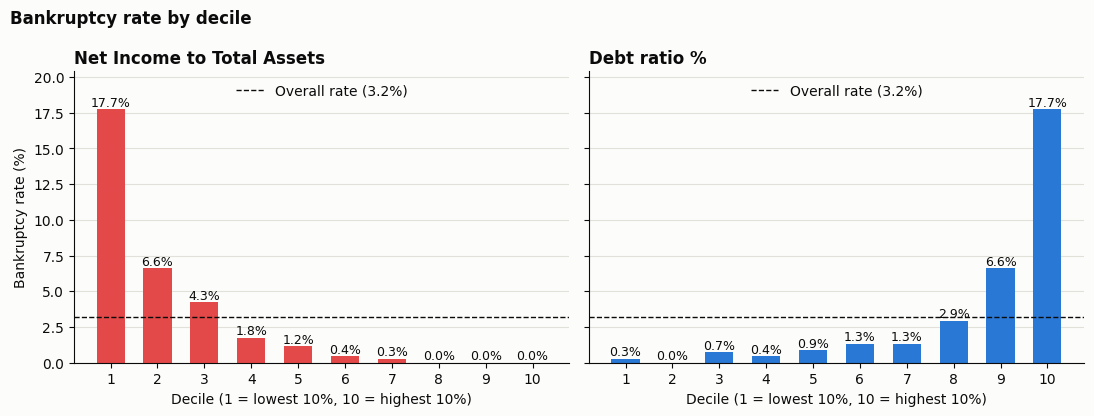

In [ ]:
# Figure 2.6: bankruptcy rate by decile ("risk ladder")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, color in zip(axes, (PROFIT, DEBT), (RED, BLUE)):
    rate = ladder[col]['rate'] * 100
    ax.bar(rate.index.astype(str), rate.values, color=color, width=0.6)
    ax.axhline(BASE_RATE * 100, color=INK, linestyle='--', linewidth=1, label=f'Overall rate ({BASE_RATE:.1%})')
    for x, v in enumerate(rate.values):
        ax.text(x, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=9)
    ax.grid(axis='y')
    ax.set_xlabel('Decile (1 = lowest 10%, 10 = highest 10%)')
    ax.set_title(col)
    ax.legend(frameon=False, loc='upper center')
axes[0].set_ylabel('Bankruptcy rate (%)')
axes[0].set_ylim(0, ladder[PROFIT]['rate'].max() * 100 * 1.15)
fig.suptitle('Bankruptcy rate by decile', fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('2.6 risk_ladder_by_decile')
plt.show()

In [ ]:
# Profit x debt quadrants, split at the median of each feature
profit_lvl = np.where(df[PROFIT] >= df[PROFIT].median(), 'High profit', 'Low profit')
debt_lvl = np.where(df[DEBT] >= df[DEBT].median(), 'High debt', 'Low debt')

quad = df.groupby([profit_lvl, debt_lvl])['Bankrupt?'].agg(companies='count', bankrupt='sum', rate='mean')
quad.index.names = ['Profit', 'Debt']
quad['share_of_companies'] = quad['companies'] / len(df)
quad['share_of_bankruptcies'] = quad['bankrupt'] / quad['bankrupt'].sum()
quad

companies  bankrupt      rate  share_of_companies  \
Profit      Debt                                                           
High profit High debt       1311         5  0.003814            0.192257   
            Low debt        2099         0  0.000000            0.307816   
Low profit  High debt       2100       199  0.094762            0.307963   
            Low debt        1309        16  0.012223            0.191964   

                       share_of_bankruptcies  
Profit      Debt                              
High profit High debt               0.022727  
            Low debt                0.000000  
Low profit  High debt               0.904545  
            Low debt                0.072727

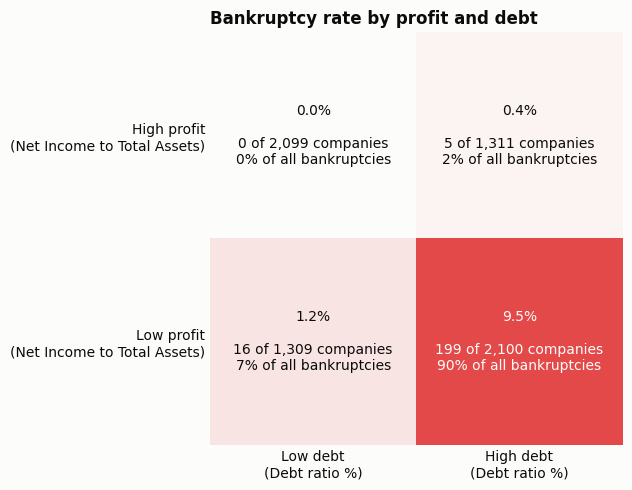

In [ ]:
# Figure 2.7: bankruptcy rate in each profit x debt quadrant
from matplotlib.colors import LinearSegmentedColormap

rows, cols = ['High profit', 'Low profit'], ['Low debt', 'High debt']
rate_grid = np.array([[quad.loc[(r, c), 'rate'] for c in cols] for r in rows])

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(rate_grid, cmap=LinearSegmentedColormap.from_list('risk', [SURFACE, RED]), vmin=0, vmax=rate_grid.max())
for i, r in enumerate(rows):
    for j, c in enumerate(cols):
        q = quad.loc[(r, c)]
        ax.text(j, i, f"{q['rate']:.1%}\n\n{q['bankrupt']:.0f} of {q['companies']:,.0f} companies\n"
                      f"{q['share_of_bankruptcies']:.0%} of all bankruptcies",
                ha='center', va='center', color=SURFACE if q['rate'] > rate_grid.max() / 2 else INK)
ax.set_xticks(range(2), [f'{c}\n({DEBT})' for c in cols])
ax.set_yticks(range(2), [f'{r}\n({PROFIT})' for r in rows])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title('Bankruptcy rate by profit and debt')
plt.tight_layout()
save_fig('2.7 profit_debt_quadrants')
plt.show()

### Red flags

The Liability-Assets Flag covers only 8 companies, so its rate is indicative only. *Lift* is the bankruptcy rate divided by the overall rate.

In [ ]:
# Red flags: bankruptcy rate of companies that meet each condition
low_profit10 = df[PROFIT] <= df[PROFIT].quantile(0.10)
high_debt10 = df[DEBT] >= df[DEBT].quantile(0.90)
flags = {
    'Liabilities exceed assets (Liability-Assets Flag = 1)': df['Liability-Assets Flag'] == 1,
    f'Bottom 10% {PROFIT}': low_profit10,
    f'Top 10% {DEBT}': high_debt10,
    'Bottom 10% profit and top 10% debt': low_profit10 & high_debt10,
    'Below-median profit and above-median debt': (profit_lvl == 'Low profit') & (debt_lvl == 'High debt'),
}
red_flags = pd.DataFrame({name: {'companies': mask.sum(), 'bankrupt': df.loc[mask, 'Bankrupt?'].sum()}
                          for name, mask in flags.items()}).T
red_flags['rate'] = red_flags['bankrupt'] / red_flags['companies']
red_flags['lift'] = (red_flags['rate'] / BASE_RATE).round(1)
red_flags['share_of_bankruptcies'] = red_flags['bankrupt'] / df['Bankrupt?'].sum()
red_flags

,companies,bankrupt,rate,lift,share_of_bankruptcies
Liabilities exceed assets (Liability-Assets Flag = 1),8,6,0.750000,23.2,0.027273
Bottom 10% Net Income to Total Assets,682,121,0.177419,5.5,0.550000
Top 10% Debt ratio %,682,121,0.177419,5.5,0.550000
Bottom 10% profit and top 10% debt,169,73,0.431953,13.4,0.331818
Below-median profit and above-median debt,2100,199,0.094762,2.9,0.904545


### K-Means clusters

Eight features covering profitability, leverage, liquidity and cash. Many features contain extreme values (up to 1e9), so each one is mapped to a normal shape with a quantile transform before clustering. k = 4 gives the clearest, nameable segments (silhouette scores for k = 3 to 5 are close, about 0.17 to 0.19). The bankruptcy label is not used to build the clusters, only to describe them afterwards.

In [ ]:
# K-Means on quantile-transformed features; clusters are then named from their profile
from sklearn.cluster import KMeans
from sklearn.preprocessing import QuantileTransformer

CLUSTER_FEATURES = [PROFIT, 'Retained Earnings to Total Assets', DEBT, 'Borrowing dependency',
                    'Current Liability to Assets', 'Working Capital to Total Assets',
                    'Cash/Total Assets', 'Cash Flow to Total Assets']
X_seg = pd.DataFrame(QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=42)
                     .fit_transform(df[CLUSTER_FEATURES]), columns=CLUSTER_FEATURES)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_seg)

# Names follow the profile table below, ordered from lowest to highest bankruptcy rate
CLUSTER_NAMES = ['Cash-rich earners', 'Steady middle', 'Low profit, low debt', 'Loss-making and over-borrowed']
order = df.groupby(kmeans.labels_)['Bankrupt?'].mean().sort_values().index
cluster = pd.Series(kmeans.labels_).map(dict(zip(order, CLUSTER_NAMES)))

clusters = df.groupby(cluster)['Bankrupt?'].agg(companies='count', bankrupt='sum', rate='mean').reindex(CLUSTER_NAMES)
clusters['share_of_companies'] = clusters['companies'] / len(df)
clusters['share_of_bankruptcies'] = clusters['bankrupt'] / clusters['bankrupt'].sum()
clusters.index.name = 'Cluster'
clusters

,companies,bankrupt,rate,share_of_companies,share_of_bankruptcies
Cluster,,,,,
Cash-rich earners,1429,0,0.000000,0.209562,0.000000
Steady middle,2419,9,0.003721,0.354744,0.040909
"Low profit, low debt",1267,15,0.011839,0.185804,0.068182
Loss-making and over-borrowed,1704,196,0.115023,0.249890,0.890909


In [ ]:
# Cluster profile: mean of each transformed feature (0 = typical company, + = above, - = below)
profile = X_seg.groupby(cluster).mean().reindex(CLUSTER_NAMES).T.round(2)
profile

,Cash-rich earners,Steady middle,"Low profit, low debt",Loss-making and over-borrowed
Net Income to Total Assets,1.07,0.34,-0.71,-0.85
Retained Earnings to Total Assets,1.02,0.35,-0.69,-0.85
Debt ratio %,-0.85,0.21,-0.91,1.08
Borrowing dependency,-0.91,0.12,-0.59,1.10
Current Liability to Assets,-0.60,0.22,-0.94,0.89
Working Capital to Total Assets,0.98,-0.14,0.31,-0.86
Cash/Total Assets,1.03,-0.15,0.05,-0.69
Cash Flow to Total Assets,0.71,-0.00,-0.40,-0.29


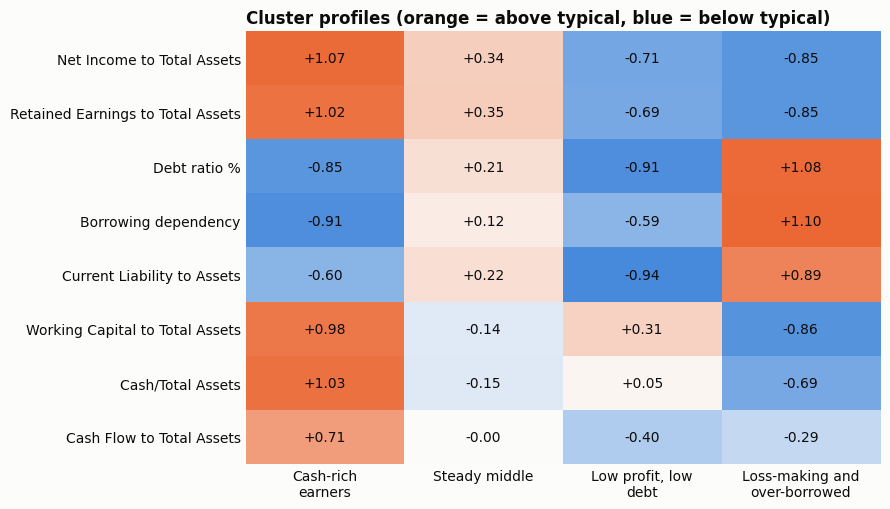

In [ ]:
# Figure 2.8: cluster profiles
fig, ax = plt.subplots(figsize=(9, 5.2))
lim = profile.abs().max().max()
ax.imshow(profile.values, cmap=LinearSegmentedColormap.from_list('div', [BLUE, SURFACE, ORANGE]),
          vmin=-lim, vmax=lim, aspect='auto')
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        ax.text(j, i, f'{profile.iat[i, j]:+.2f}', ha='center', va='center')
ax.set_xticks(range(profile.shape[1]), [textwrap.fill(c, 16) for c in profile.columns])
ax.set_yticks(range(profile.shape[0]), profile.index)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title('Cluster profiles (orange = above typical, blue = below typical)')
plt.tight_layout()
save_fig('2.8 cluster_profiles')
plt.show()

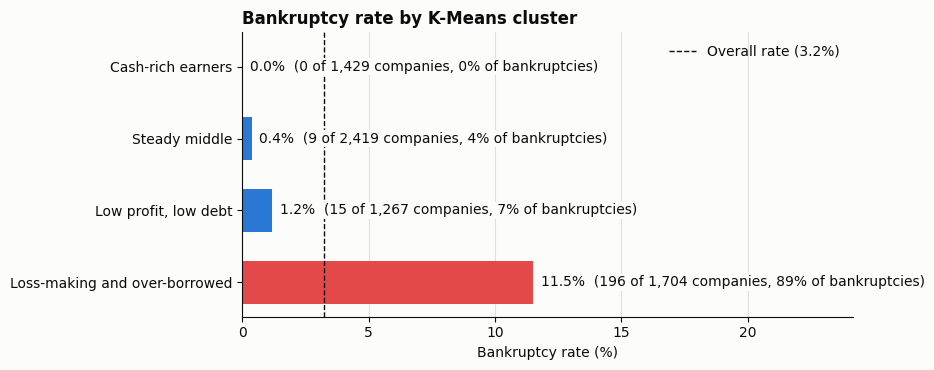

In [ ]:
# Figure 2.9: bankruptcy rate by cluster
fig, ax = plt.subplots(figsize=(9, 3.8))
plot_df = clusters.iloc[::-1]
ax.barh(plot_df.index, plot_df['rate'] * 100, height=0.6,
        color=[RED if n == CLUSTER_NAMES[-1] else BLUE for n in plot_df.index])
ax.axvline(BASE_RATE * 100, color=INK, linestyle='--', linewidth=1, label=f'Overall rate ({BASE_RATE:.1%})')
for y, (_, r) in enumerate(plot_df.iterrows()):
    ax.text(r['rate'] * 100 + 0.3, y, f"{r['rate']:.1%}  ({r['bankrupt']:.0f} of {r['companies']:,.0f} companies, "
                                f"{r['share_of_bankruptcies']:.0%} of bankruptcies)", va='center',
            bbox=dict(facecolor=SURFACE, edgecolor='none', pad=1))
ax.grid(axis='x')
ax.set_xlabel('Bankruptcy rate (%)')
ax.set_xlim(0, clusters['rate'].max() * 100 * 2.1)
ax.set_title('Bankruptcy rate by K-Means cluster')
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
save_fig('2.9 bankruptcy_rate_by_cluster')
plt.show()

In [ ]:
# Save the full dataset with the segment labels (all rows and original columns, no outliers removed)
segmented = df.copy()
segmented['Profit level'] = profit_lvl
segmented['Debt level'] = debt_lvl
segmented['Cluster'] = cluster.values
segmented.to_csv('data_bankruptcy_segmented.csv', index=False)
print(f'Saved data_bankruptcy_segmented.csv: {segmented.shape[0]} rows, {segmented.shape[1]} columns')
segmented['Cluster'].value_counts()

Saved data_bankruptcy_segmented.csv: 6819 rows, 99 columns


Cluster
Steady middle                    2419
Loss-making and over-borrowed    1704
Cash-rich earners                1429
Low profit, low debt             1267
Name: count, dtype: int64

# 3. Modelling with XGBoost

Two models are compared, using the same train-test split and the same 10-fold cross-validation:

| Model | Description |
|---|---|
| **Baseline** | XGBoost with default settings and all features |
| **Engineered** | Feature selection, IQR outlier removal, SMOTE and hyperparameter tuning |

The data is split **first** (80% train, 20% test, stratified). The test set is not touched until the final comparison. All engineering steps sit inside one pipeline, so within each cross-validation fold they are fitted on that fold's training part only, and SMOTE never sees validation or test data. Models are compared mainly on **accuracy** and **recall** (the share of bankrupt companies that are caught). Because only 3.2% of companies are bankrupt, accuracy alone is misleading: a model that predicts "not bankrupt" for every company already scores 96.8%. Recall shows whether the bankrupt companies are actually found. PR-AUC, which does not depend on a threshold, is used to tune the engineered model.

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (accuracy_score, average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from xgboost import XGBClassifier
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

RANDOM_STATE = 42

X = df.drop(columns='Bankrupt?')
y = df['Bankrupt?']

# Split first: the test set is not touched until the final comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

pd.DataFrame({'rows': [len(y_train), len(y_test)],
              'bankrupt': [int(y_train.sum()), int(y_test.sum())]}, index=['Train', 'Test'])

In [ ]:
SCORING = {'Accuracy': 'accuracy', 'Recall': 'recall', 'PR-AUC': 'average_precision',
           'ROC-AUC': 'roc_auc', 'Precision': 'precision', 'F1': 'f1'}

def evaluate(model):
    """10-fold CV on the training set, then fit on all training data and score the test set."""
    cv_res = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_row = {m: f"{cv_res['test_' + m].mean():.3f} ± {cv_res['test_' + m].std():.3f}" for m in SCORING}

    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_row = {'Accuracy': accuracy_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                'PR-AUC': average_precision_score(y_test, proba), 'ROC-AUC': roc_auc_score(y_test, proba),
                'Precision': precision_score(y_test, pred), 'F1': f1_score(y_test, pred)}
    return cv_row, test_row, proba

## 3.1 Baseline Model

Default XGBoost on all 95 features, with no outlier removal, no resampling and no tuning.

In [ ]:
baseline = XGBClassifier(random_state=RANDOM_STATE, n_jobs=1)
baseline_cv, baseline_test, baseline_proba = evaluate(baseline)
pd.DataFrame([baseline_cv], index=['Baseline: 10-fold CV (mean ± SD)'])

## 3.2 Engineered Model

**Steps, in order** (all fitted on training data only):

1. **Feature selection.** Keep the top *n* features ranked by XGBoost importance. Unlike ranking by correlation, this captures nonlinear effects and copes with the duplicated features found in Section 2.
2. **IQR outlier removal.** Remove rows outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR] on any selected feature, using fences from the training data. Only **non-bankrupt** rows are removed. Applying the rule to every row and all 95 features would delete about 93% of the data and nearly every bankrupt company, because bankrupt companies are outliers far more often than healthy ones.
3. **SMOTE.** Create synthetic bankrupt examples so the classes are balanced in the training data only.
4. **Tuned XGBoost.** Hyperparameters are chosen by randomized search with 10-fold CV, scored by PR-AUC. Randomized search is preferred to grid search because it covers a large space in far fewer runs.

| Parameter | Range |
|---|---|
| `select__max_features` (number of features) | 10 – 40 |
| `clf__n_estimators` | 100 – 500 |
| `clf__learning_rate` | 0.01 – 0.2 (log scale) |
| `clf__max_depth` | 2 – 6 |
| `clf__min_child_weight` | 1 – 10 |
| `clf__subsample` | 0.6 – 1.0 |
| `clf__colsample_bytree` | 0.5 – 1.0 |

In [ ]:
def remove_iqr_outliers(X, y, k=1.5):
    """Drop non-bankrupt rows outside [Q1 - k*IQR, Q3 + k*IQR] on any feature. Bankrupt rows are kept."""
    X, y = np.asarray(X), np.asarray(y)
    q1, q3 = np.percentile(X, [25, 75], axis=0)
    iqr = q3 - q1
    is_outlier = ((X < q1 - k * iqr) | (X > q3 + k * iqr)).any(axis=1)
    keep = ~(is_outlier & (y == 0))
    return X[keep], y[keep]

# Selector: the n features with the highest XGBoost importance (n is tuned below)
selector = SelectFromModel(
    XGBClassifier(n_estimators=200, max_depth=3, random_state=RANDOM_STATE, n_jobs=1,
                  scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()),
    threshold=-np.inf)

engineered = Pipeline([
    ('select', selector),
    ('outliers', FunctionSampler(func=remove_iqr_outliers)),   # applied to training data only
    ('smote', SMOTE(random_state=RANDOM_STATE)),               # applied to training data only
    ('clf', XGBClassifier(random_state=RANDOM_STATE, n_jobs=1)),
])

param_dist = {
    'select__max_features':  randint(10, 41),
    'clf__n_estimators':     randint(100, 501),
    'clf__learning_rate':    loguniform(0.01, 0.2),
    'clf__max_depth':        randint(2, 7),
    'clf__min_child_weight': randint(1, 11),
    'clf__subsample':        uniform(0.6, 0.4),
    'clf__colsample_bytree': uniform(0.5, 0.5),
}

search = RandomizedSearchCV(engineered, param_dist, n_iter=30, scoring='average_precision',
                            cv=cv, n_jobs=-1, random_state=RANDOM_STATE, refit=True, verbose=1)
search.fit(X_train, y_train)

print(f'Best CV PR-AUC: {search.best_score_:.4f}')
pd.Series(search.best_params_, name='best value')

In [ ]:
engineered_cv, engineered_test, engineered_proba = evaluate(search.best_estimator_)
pd.DataFrame([engineered_cv], index=['Engineered: 10-fold CV (mean ± SD)'])

## 3.3 Model Comparison

The CV scores of the engineered model are slightly optimistic because the same folds were used to pick its hyperparameters, so the **test set** is the fair comparison. It contains only 44 bankrupt companies, so differences of a few hundredths are within the noise. Accuracy, recall, precision and F1 use the default threshold of 0.5.

In [ ]:
print('10-fold CV on the training set (mean ± SD):')
display(pd.DataFrame([baseline_cv, engineered_cv], index=['Baseline', 'Engineered']))

print('\nHeld-out test set:')
results = pd.DataFrame([baseline_test, engineered_test], index=['Baseline', 'Engineered'])
# Reference: a model that predicts "not bankrupt" for every company
results.loc['Always "not bankrupt"'] = {'Accuracy': 1 - y_test.mean(), 'Recall': 0.0}
results.round(3)

In [ ]:
# Figure 3.1: precision-recall curves on the test set
COLORS = {'Baseline': BLUE, 'Engineered': '#1baf7a'}

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for name, proba in [('Baseline', baseline_proba), ('Engineered', engineered_proba)]:
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, color=COLORS[name], linewidth=2,
            label=f'{name} (PR-AUC = {average_precision_score(y_test, proba):.3f})')
ax.axhline(y_test.mean(), color=INK, linestyle='--', linewidth=1,
           label=f'No skill (bankrupt rate = {y_test.mean():.3f})')
ax.grid(True)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-recall curves on the test set')
ax.legend(frameon=False, loc='upper right')
plt.tight_layout()
save_fig('3.1 precision_recall_test')
plt.show()

In [ ]:
# Figure 3.2: confusion matrices on the test set (threshold 0.5)
# Cell colour = share of the actual class (row); each cell also shows the count.
from matplotlib.colors import LinearSegmentedColormap
cm_cmap = LinearSegmentedColormap.from_list('seq', ['#ffffff', BLUE])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, (name, proba) in zip(axes, [('Baseline', baseline_proba), ('Engineered', engineered_proba)]):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    cm_row = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_row, cmap=cm_cmap, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}\n({cm_row[i, j]:.1%})', ha='center', va='center', fontsize=12,
                    color='white' if cm_row[i, j] > 0.5 else INK)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Not bankrupt', 'Bankrupt'])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Not bankrupt', 'Bankrupt'])
    ax.set_xlabel('Predicted', labelpad=8)
    ax.set_ylabel('Actual')
    ax.set_title(name)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.tight_layout()
save_fig('3.2 confusion_matrices_test')
plt.show()

In [ ]:
# Figure 3.3: importance (gain) of the features used by the engineered model
best = search.best_estimator_
selected = X_train.columns[best.named_steps['select'].get_support()]
importance = pd.Series(best.named_steps['clf'].feature_importances_, index=selected).sort_values()
top = importance.tail(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.grid(axis='x')
ax.set_xlabel('Feature importance (gain, normalised)')
ax.set_title(f'Top 15 of the {len(importance)} features used by the engineered model')
for y_i, v in enumerate(top.values):
    ax.text(v, y_i, f' {v:.3f}', va='center', color=INK)
ax.set_xlim(0, top.max() * 1.12)
plt.tight_layout()
save_fig('3.3 feature_importance_engineered')
plt.show()

## 3.4 Summary

The numbers come from the run with `random_state = 42`. Accuracy and recall use the default threshold of 0.5.

| Test set | Accuracy | Recall | PR-AUC | Precision |
|---|---|---|---|---|
| Baseline | 0.968 | 0.295 | 0.504 | 0.520 |
| Engineered | 0.746 | 0.977 | 0.403 | 0.111 |
| Always predicts "not bankrupt" | 0.968 | 0.000 | – | – |

- **Accuracy alone would be misleading.** The baseline's accuracy (0.968) is the same as a rule that never predicts bankruptcy. Its recall shows the difference: it finds only 13 of the 44 bankrupt companies in the test set (29.5%).
- **The engineered model finds almost all bankrupt companies but pays in accuracy.** Recall rises to 0.977 (43 of 44 caught), while accuracy falls to 0.746 because it flags about 28% of all companies as bankrupt, most of them wrongly (precision 0.111).
- **Which is better depends on the priority.** If catching bankruptcies matters most, the engineered model wins on recall. If overall accuracy and few false alarms matter most, the baseline wins.
- **The engineered model ranks companies less well.** The threshold-free PR-AUC is higher for the baseline (0.504 against 0.403 on the test set, and 0.498 against 0.426 in cross-validation). The engineered model's high recall therefore comes mainly from flagging more companies at the 0.5 threshold, not from a better ranking. Two steps drive this: IQR outlier removal takes extreme values out of healthy companies only, so the model learns that an extreme value means bankruptcy, and SMOTE balances the classes 1:1, which pushes predicted probabilities upward. Lowering the decision threshold of the baseline also trades accuracy for recall, without the extra steps.
- **Feature selection did not reduce the model much.** The search chose the maximum allowed number of features (40).

The test set has only 44 bankrupt companies, so recall values move in steps of about 0.02 per company and should be read with caution.